# Supplementary Figures 5 and 6 — the CNN predictors

**S5** Predictivity across the seven read-out layers of each network.
**S6** What happens when the face is occluded before the CNN feature is computed.

The CNN feature is the representational distance between a scene with a face and
the same scene without one, so it asks how much the face changes the network's
response. The main analyses use the final layer.

The untrained network is a randomly initialised copy of the same architecture. It
is genuinely untrained: its face/no-face distance *contracts* with depth, as
random weights progressively wash out the input difference, whereas both trained
networks amplify it.

In [1]:
import sys
from pathlib import Path

# The notebooks live next to the code, so the package is importable without
# installing anything. Nothing outside this release is referenced.
sys.path.insert(0, str(Path.cwd().parent / "code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from facescenes import config as cfg
from facescenes import data as D
from facescenes import behaviour as B
from facescenes import encoding as E
from facescenes import onset_gaze as G
from facescenes import plotting as P
from facescenes import stats as S

P.use_style()
print("stimuli    :", len(D.stimulus_names()))
for t in cfg.TASKS:
    print(f"{t:14s}: {len(D.participant_ids(t))} participants, "
          f"{len(D.analysable_images(t))} images")

stimuli    : 120


facedetection : 38 participants, 108 images


movingwindow  : 38 participants, 120 images


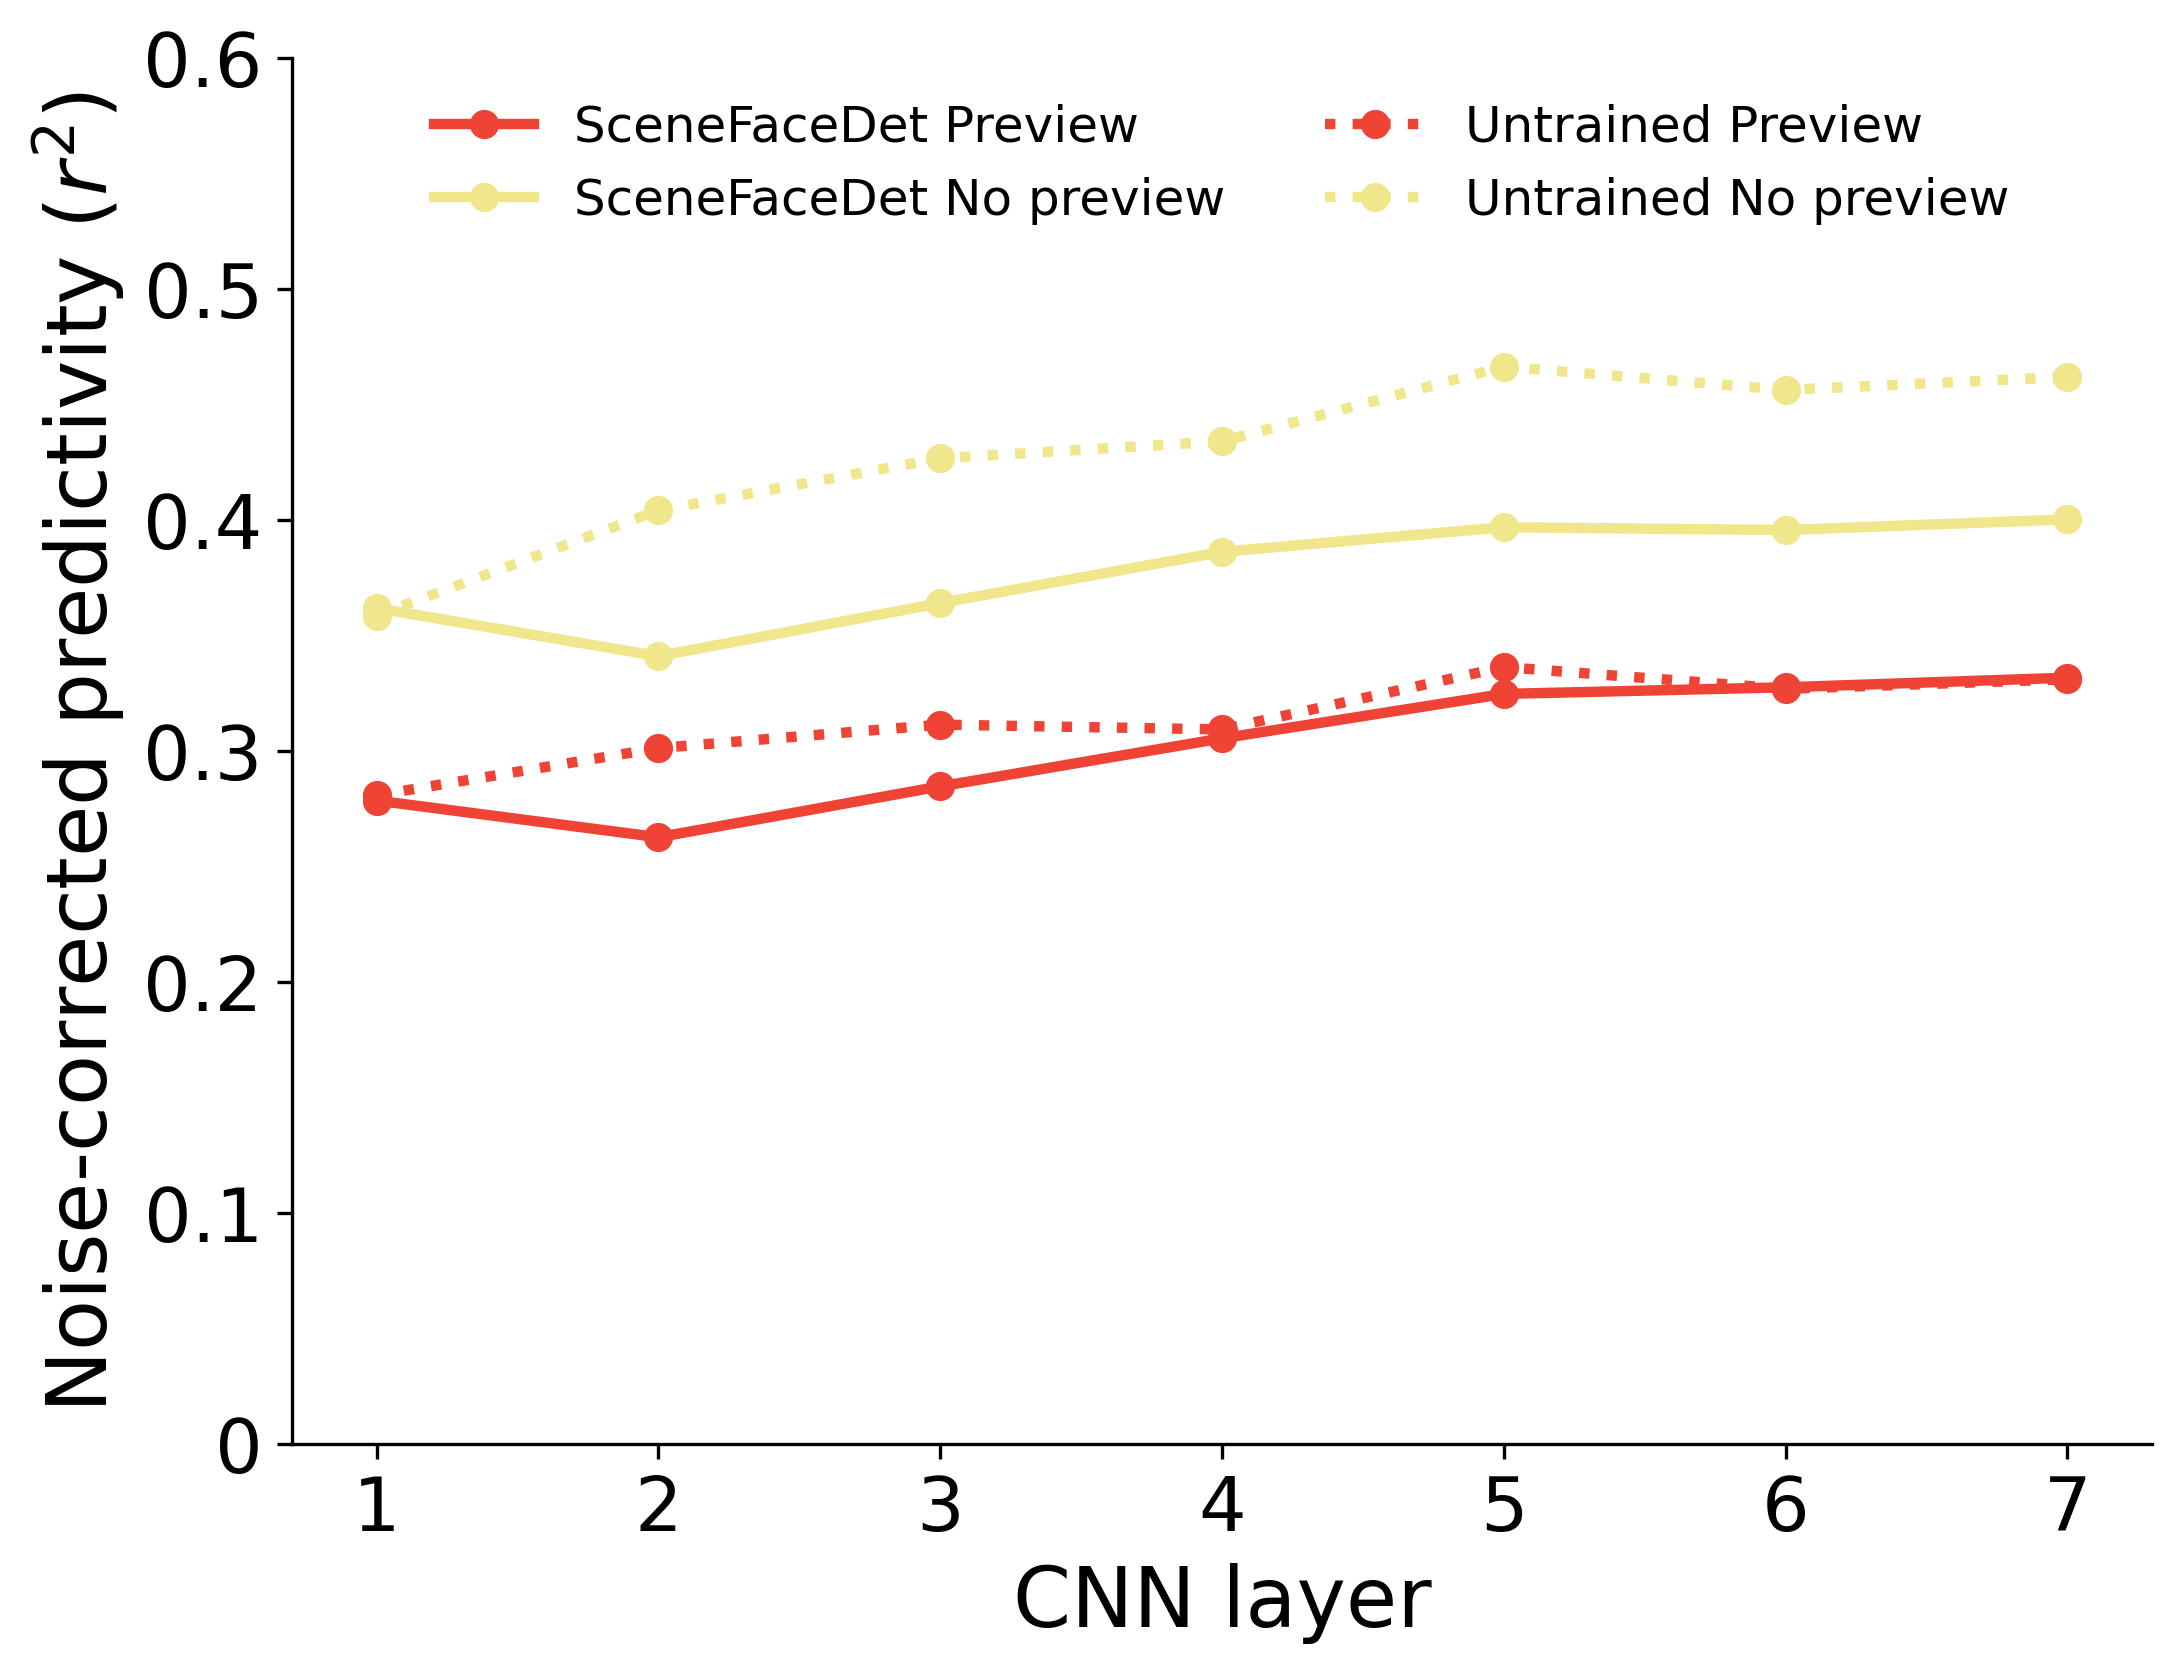

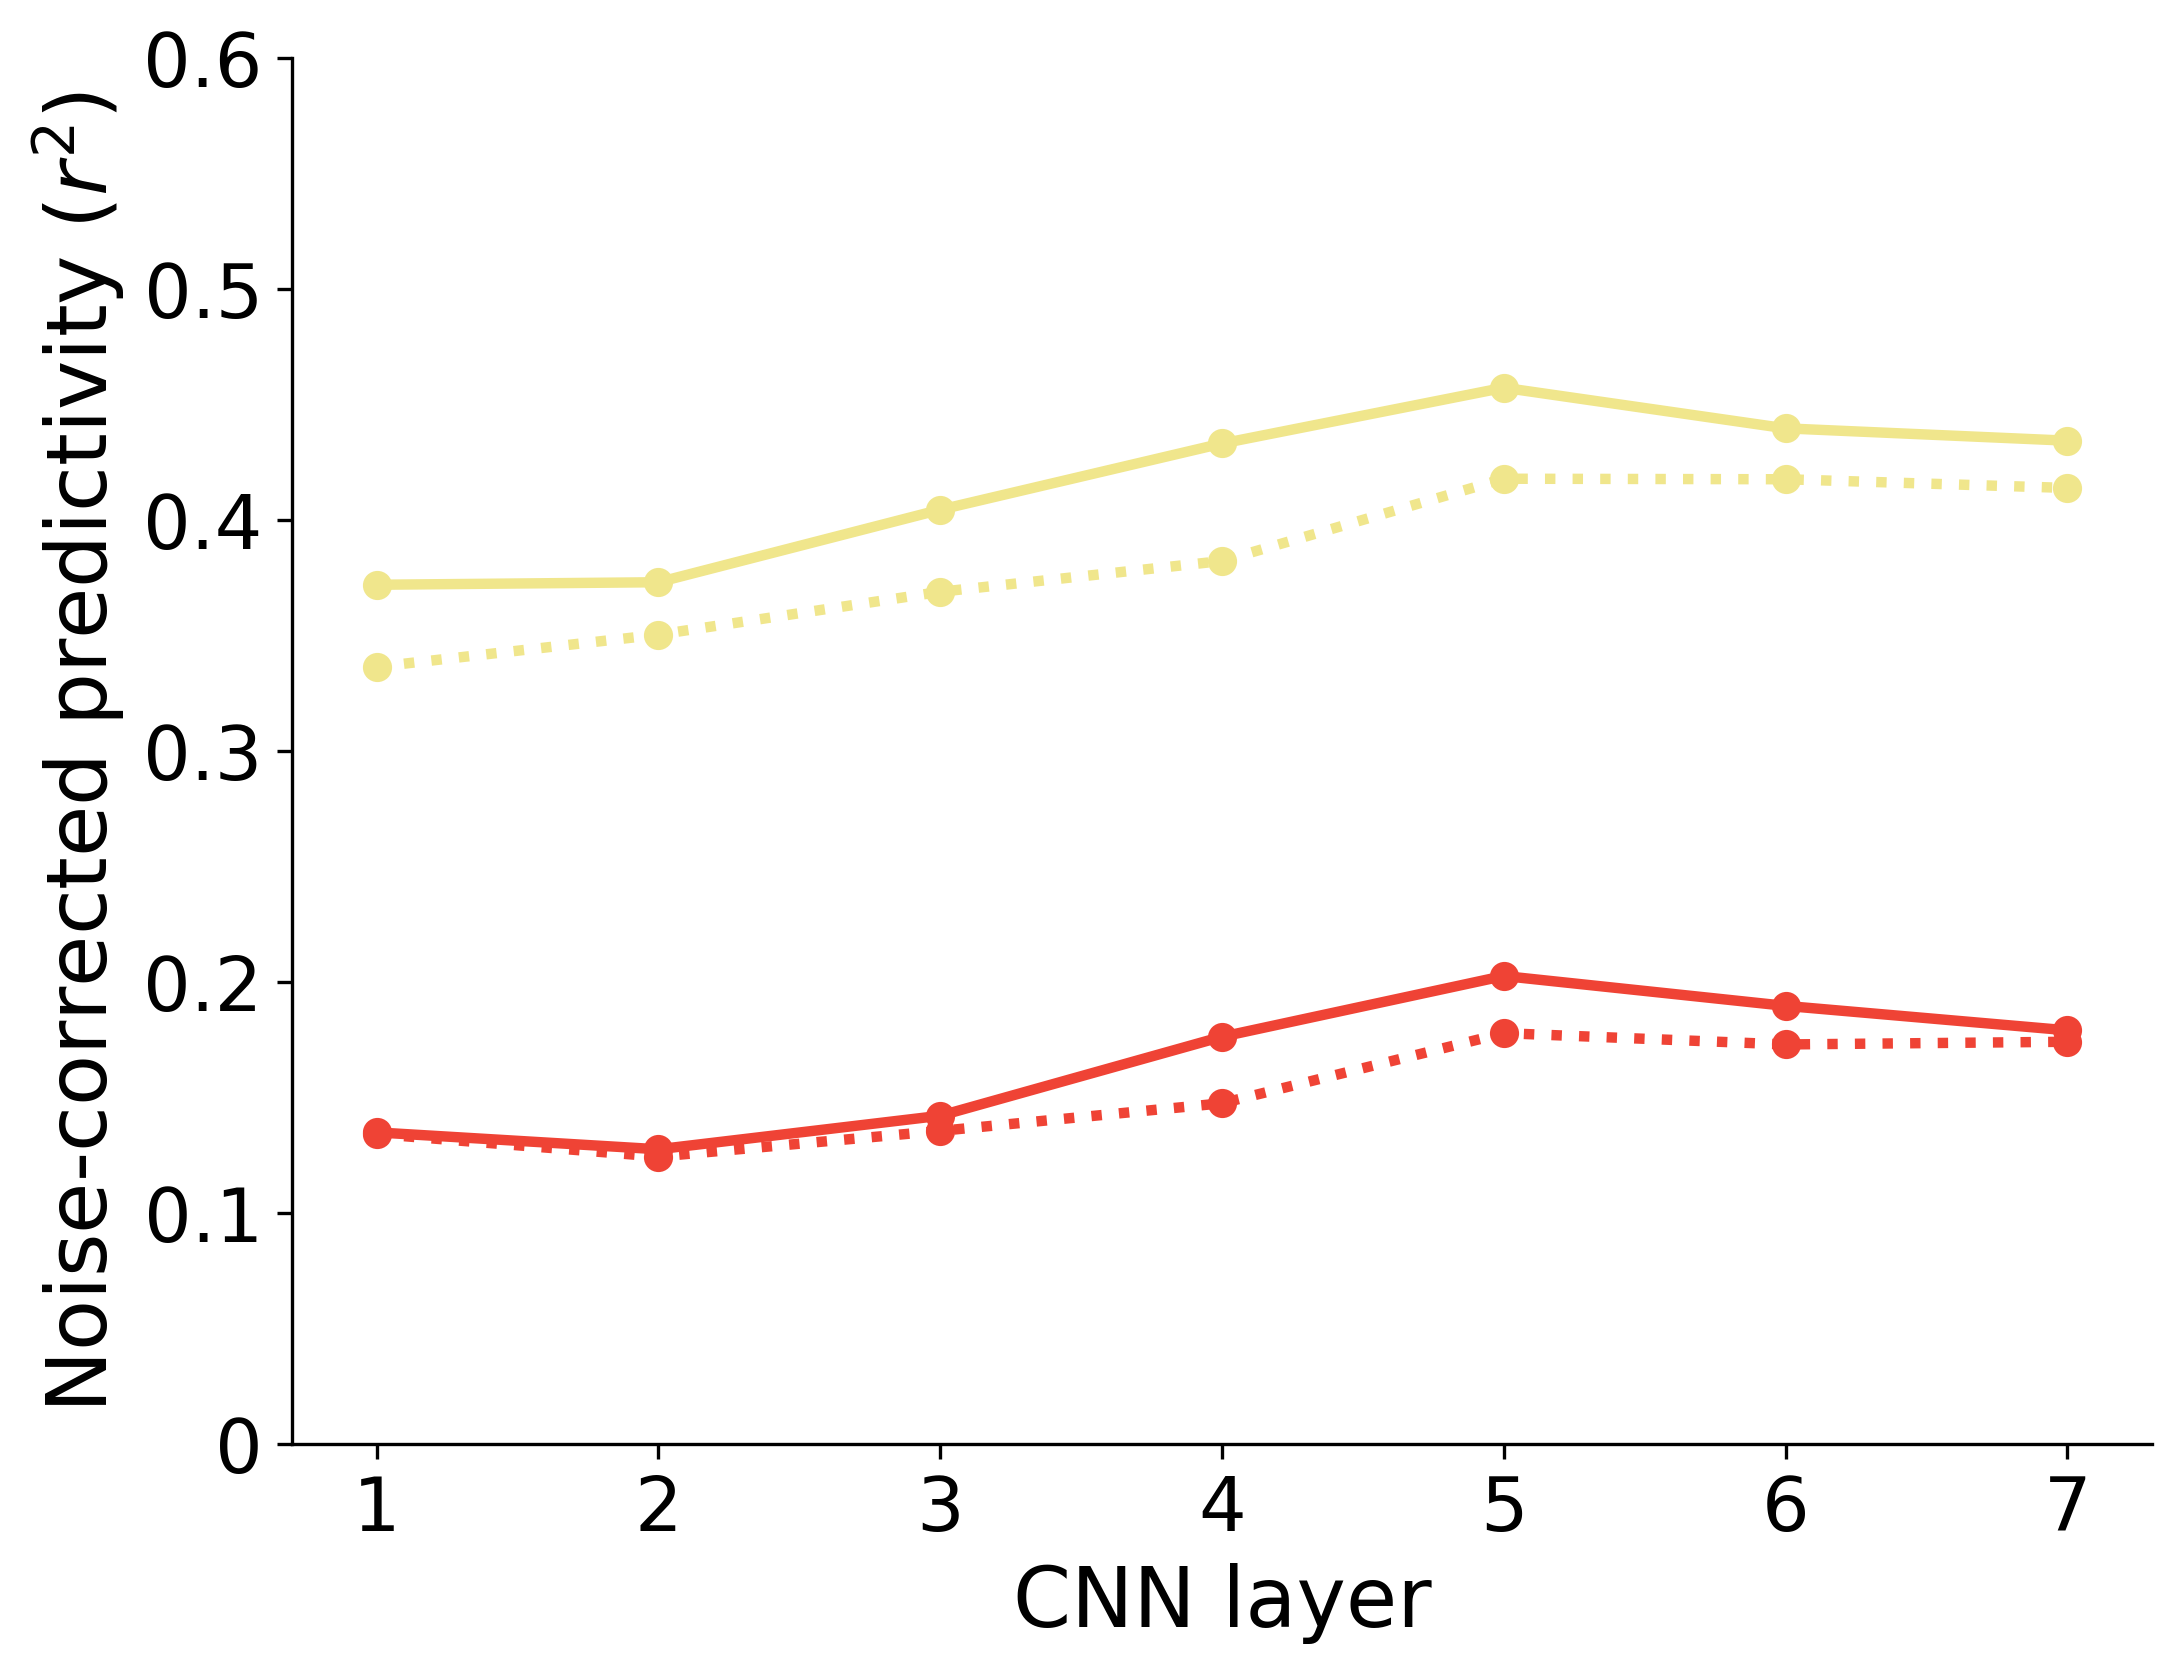

In [2]:
# The layer-depth correlations quoted in the text: python3 run_layer_depth.py
N_LAYERS = E.N_CNN_LAYERS
NETWORKS = {"SceneFaceDet": "cnn_scenefacedet.npz", "UntrainedCNN": "cnn_untrained.npz"}
NET_LABEL = {"SceneFaceDet": "SceneFaceDet", "UntrainedCNN": "Untrained"}

for task, fname in (("facedetection", "suppfig5a_layers_face_detection.png"),
                    ("movingwindow", "suppfig5b_layers_moving_window.png")):
    fig, ax = plt.subplots(figsize=(8, 6))
    rows = []
    for net, npz in NETWORKS.items():
        r = E.layer_predictivity(task, npz)
        for cond in cfg.CONDITIONS:
            rows += [dict(network=NET_LABEL[net], condition=cond, layer=k + 1, r2=v)
                     for k, v in enumerate(r[cond])]
            ax.plot(range(1, N_LAYERS + 1), r[cond],
                    color=P.condition_colours()[cond],
                    linestyle="-" if net == "SceneFaceDet" else ":",
                    marker="o", lw=2.5, ms=6,
                    label=f"{NET_LABEL[net]} {cfg.COND_LABEL[cond]}")
    # Fixed range so the two panels match; fail loudly rather than clip a value.
    vals = [row["r2"] for row in rows]
    assert 0 <= min(vals) and max(vals) <= 0.6, (min(vals), max(vals))
    ticks, (t0, t1) = P.zero_anchored_ticks(0, 0.6, step=0.1)
    ax.set_ylim(0, 0.6); ax.set_yticks(ticks)
    ax.set_yticklabels([f"{v:g}" for v in ticks], fontsize=P.FONT - 10)
    ax.set_xticks(range(1, N_LAYERS + 1))
    ax.tick_params(labelsize=P.FONT - 10)
    ax.set_xlabel("CNN layer", fontsize=P.FONT - 8)
    ax.set_ylabel(P.PREDICTIVITY_LABEL, fontsize=P.FONT - 8)
    P.title(ax, cfg.TASK_LABEL[task], fontsize=P.FONT - 6, pad=12)
    if task == "facedetection":
        # The two panels share these four curves, so the legend is drawn once,
        # inside the axes in the empty band above the lines.
        ax.legend(fontsize=P.FONT - 16, frameon=False, ncol=2, loc="upper center")
    P.clean(ax)
    P.save(fig, fname, pd.DataFrame(rows)); plt.show()

## S6 — face visible against face masked

Predictivity is defined over a set of images, so each cell has a single value and
there are no replicates for a factorial test. Squared prediction error does
decompose by image, so images become the replicates of a 2 (preview) x 2 (mask)
repeated-measures ANOVA. The bracket over each network is the main effect of
masking. See `run_masked_face_analyses.py` for why an earlier permutation
approach was invalid.

Error bars are the SD across the 100 folds and are descriptive only, as in
Figure 3: the folds are overlapping resamples of the same images, so their spread
reflects resampling noise rather than sampling variability, and the inference is
the image-level ANOVA.

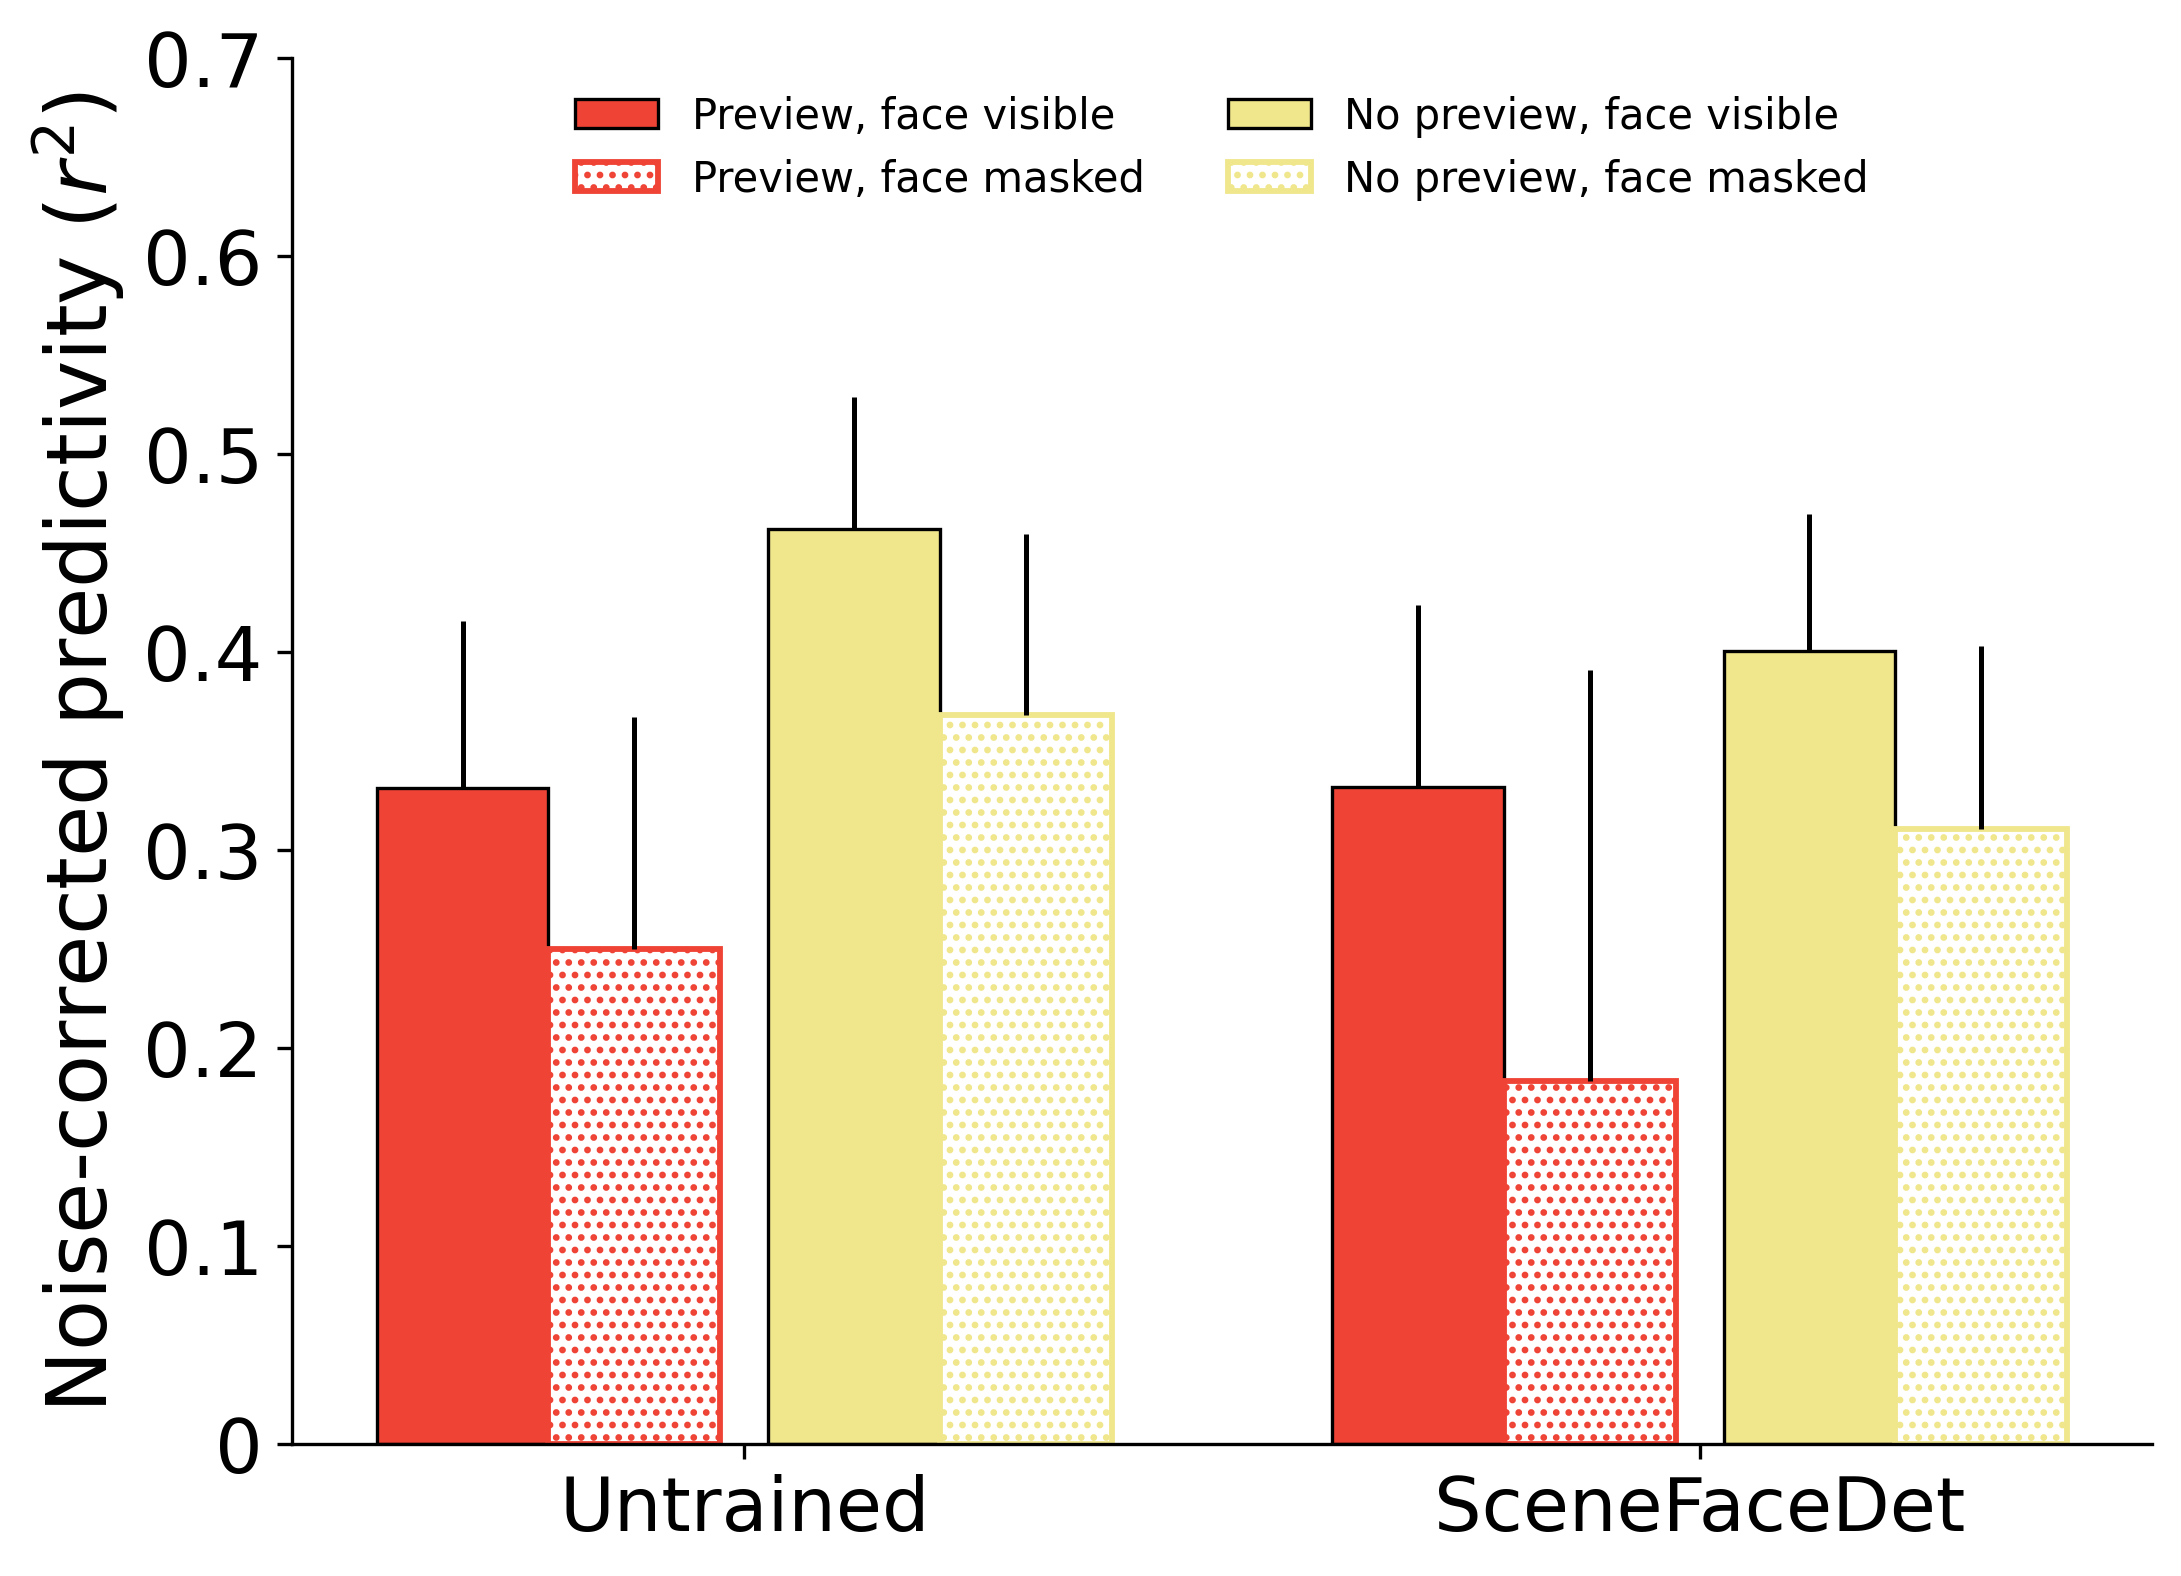

Face detection task   108 images
  Untrained
    Preview     visible +0.331+/-0.084   masked +0.250+/-0.117
    No preview  visible +0.462+/-0.067   masked +0.368+/-0.091
    preview        F(1,107) = 0.15, p = .700, η²ₚ = .001
    mask           F(1,107) = 4.86, p = .030, η²ₚ = .043
    preview x mask F(1,107) = 1.30, p = .257, η²ₚ = .012
  SceneFaceDet
    Preview     visible +0.332+/-0.092   masked +0.183+/-0.208
    No preview  visible +0.400+/-0.069   masked +0.311+/-0.092
    preview        F(1,107) = 0.34, p = .560, η²ₚ = .003
    mask           F(1,107) = 14.84, p < .001, η²ₚ = .122
    preview x mask F(1,107) = 2.54, p = .114, η²ₚ = .023


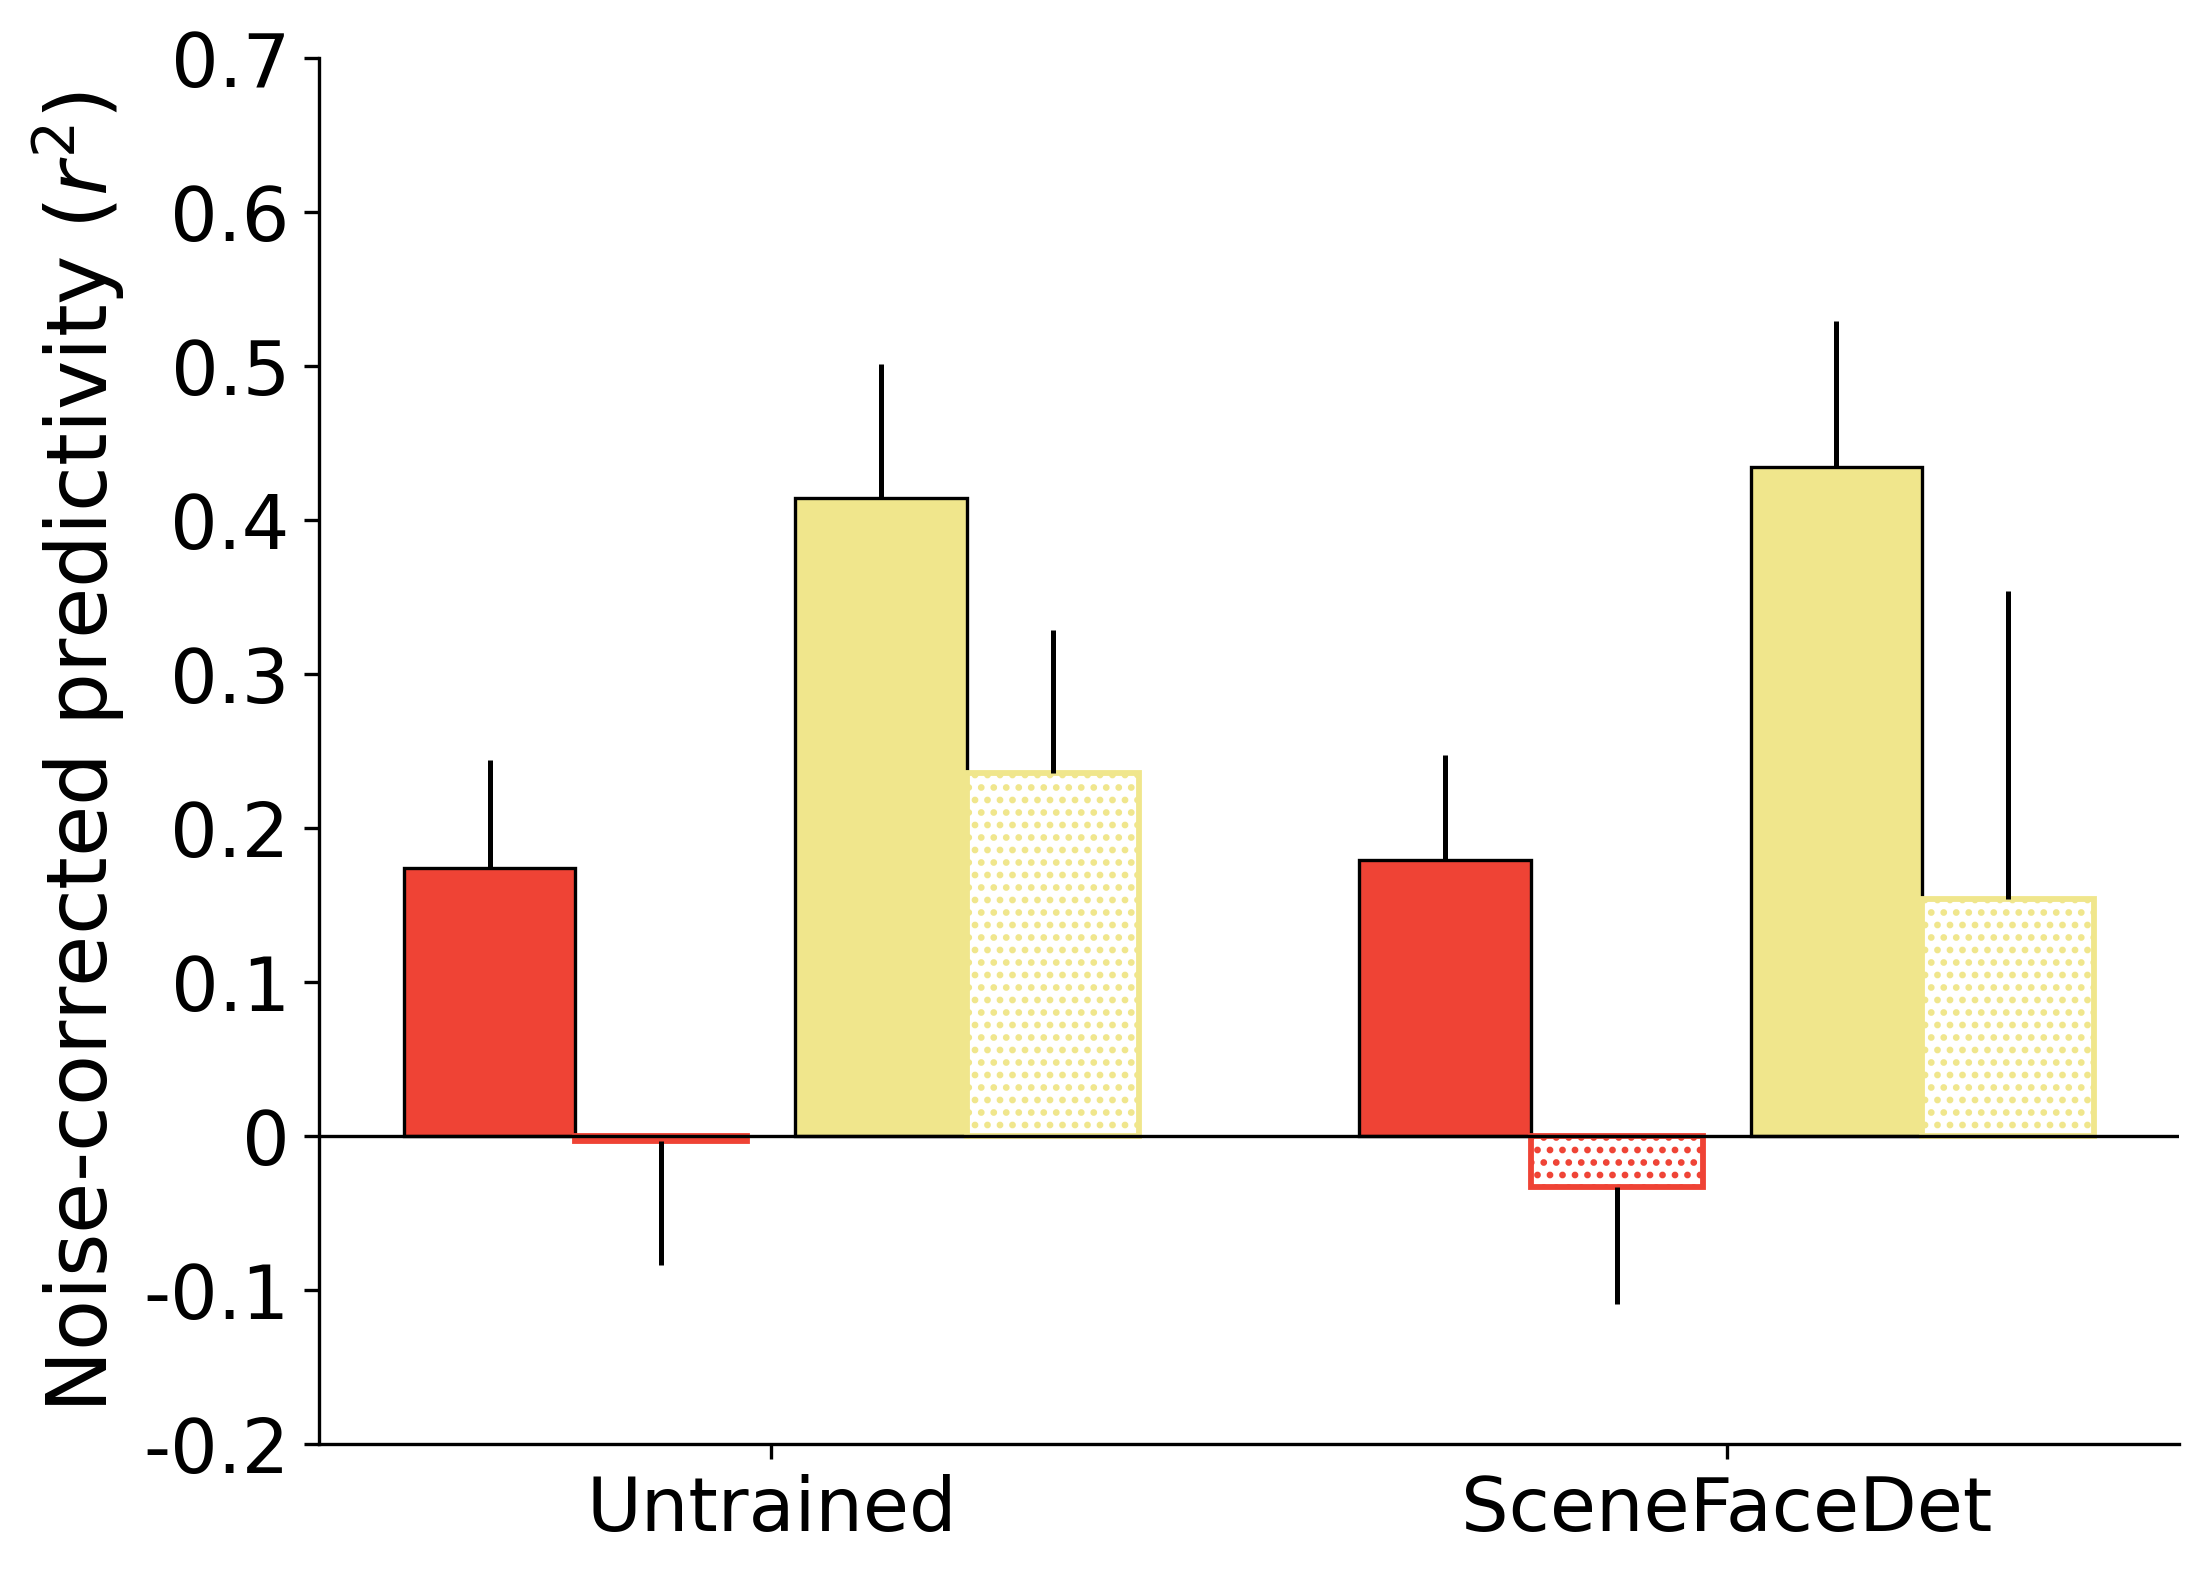

Moving-window task   120 images
  Untrained
    Preview     visible +0.174+/-0.070   masked -0.003+/-0.081
    No preview  visible +0.414+/-0.087   masked +0.236+/-0.093
    preview        F(1,119) = 0.19, p = .665, η²ₚ = .002
    mask           F(1,119) = 11.89, p < .001, η²ₚ = .091
    preview x mask F(1,119) = 5.79, p = .018, η²ₚ = .046
  SceneFaceDet
    Preview     visible +0.179+/-0.068   masked -0.033+/-0.076
    No preview  visible +0.434+/-0.095   masked +0.154+/-0.200
    preview        F(1,119) = 0.18, p = .668, η²ₚ = .002
    mask           F(1,119) = 13.92, p < .001, η²ₚ = .105
    preview x mask F(1,119) = 2.40, p = .124, η²ₚ = .020


In [3]:
import run_masked_face_analyses as MASK

# The main effect of masking is reported in the text and printed below each
# panel; set this to True to draw it on the figure as a bracket per network.
SHOW_SIGNIFICANCE = False

EFFECTS = {"A": "preview", "B": "mask", "AxB": "preview x mask"}


def anova_line(row):
    """F(df1,df2) = ..., p = ..., eta2p = ... for one effect of anova_2x2."""
    F, df1, df2, p, eta = row
    ps = "p < .001" if p < .001 else f"p = {f'{p:.3f}'[1:]}"
    return f"F({df1},{df2}) = {F:.2f}, {ps}, \u03b7\u00b2\u209a = {f'{eta:.3f}'[1:]}"

for task, fname in (("facedetection", "suppfig6a_masked_face_detection.png"),
                    ("movingwindow", "suppfig6b_masked_moving_window.png")):
    Z, y, keep, splits = E.design(task)
    n_img = len(keep)
    masked = E.masked_features(task)
    yz = np.stack([(row - np.nanmean(row)) / np.nanstd(row, ddof=1) for row in y])

    nets = list(MASK.NETWORKS)
    W, G, bars = .18, .05, []      # bar width; gap between the two condition pairs
    fig, ax = plt.subplots(figsize=(8, 6))
    tops, pvals, sds, aov = [], {}, {}, {}
    for i, net in enumerate(nets):
        col = cfg.FEATURE_NAMES.index(net)
        zv = Z[:, [col]]
        m = masked[net]; zm = ((m - m.mean()) / m.std())[:, None]
        err = np.zeros((n_img, 2, 2))
        for ci, cond in enumerate(cfg.CONDITIONS):
            err[:, ci, 0] = S.per_image_squared_error(zv, yz[ci], splits, n_img)
            err[:, ci, 1] = S.per_image_squared_error(zm, yz[ci], splits, n_img)
            for mi, z in ((0, zv), (1, zm)):
                folds = np.array(
                    [E.signed_r2(y[ci][np.setdiff1d(np.arange(n_img), tr)],
                                 E.ols_predict(z[tr], y[ci][tr],
                                               z[np.setdiff1d(np.arange(n_img), tr)]))
                     for tr in splits]) / cfg.RELIABILITY[task][cond]
                v, sd = folds.mean(), folds.std(ddof=1)
                off = (-1.5 + 2 * ci + mi) * W + (ci - .5) * G
                ax.bar(i + off, v, W,
                       color="white" if mi else P.condition_colours()[cond],
                       edgecolor=P.condition_colours()[cond] if mi else "k",
                       hatch="...." if mi else None, lw=1.4 if mi else .8,
                       label=(f"{cfg.COND_LABEL[cond]}, face "
                              f"{'masked' if mi else 'visible'}") if i == 0 else None)
                # SD across folds, drawn away from zero only, as in Figure 3.
                ax.errorbar(i + off, v, yerr=P.one_sided_errorbar([v], [sd]),
                            fmt="None", color="k", lw=1.2)
                tops.append(v + sd)
                sds[(net, cond, mi)] = (v, sd)
        aov[net] = MASK.S.anova_2x2(np.log(err))
        pvals[net] = aov[net]["B"][3]

    # Reserved whether or not the brackets are drawn, so the two panels keep the
    # same y-axis either way.
    bar_y = max(tops) * 1.15
    if SHOW_SIGNIFICANCE:
        for i, net in enumerate(nets):
            a, b = i - 1.5 * W - G / 2, i + 1.5 * W + G / 2
            ax.plot([a, a, b, b], [bar_y, bar_y + .012, bar_y + .012, bar_y],
                    lw=1.1, c="k")
            ax.text(i, bar_y + .018, P.significance(pvals[net]), ha="center",
                    va="bottom", fontsize=P.FONT - 12)

    hi = np.ceil((bar_y + .07) * 10) / 10
    # A negative bar's error bar points down, so the axis has to reach it; where
    # it does, zero is drawn explicitly.
    below = [v - sd for v, sd in sds.values() if v < 0]
    lo = np.floor(min(below + [0]) * 10) / 10
    ticks = np.arange(lo, hi + .05, .1)
    if lo < 0:
        ax.axhline(0, color="k", lw=.8)
    ax.set_ylim(lo, hi); ax.set_yticks(ticks)
    ax.set_yticklabels([f"{v:g}" for v in ticks], fontsize=P.FONT - 10)
    ax.set_xticks(range(len(nets)))
    ax.set_xticklabels([MASK.NETWORK_LABEL[n] for n in nets], fontsize=P.FONT - 10)
    ax.set_ylabel(P.PREDICTIVITY_LABEL, fontsize=P.FONT - 8)
    P.title(ax, cfg.TASK_LABEL[task], fontsize=P.FONT - 6, pad=12)
    if task == "facedetection":
        # Both panels show the same four bars, so the legend is drawn once,
        # inside the axes above them.
        ax.legend(fontsize=P.FONT - 18, frameon=False, ncol=2, loc="upper center")
    P.clean(ax)
    src = pd.DataFrame([dict(network=MASK.NETWORK_LABEL[net], condition=cond,
                             face="masked" if mi else "visible", r2=v,
                             sd_across_folds=sd)
                        for (net, cond, mi), (v, sd) in sds.items()])
    P.save(fig, fname, src); plt.show()
    print(f"{cfg.TASK_LABEL[task]}   {n_img} images")
    for net in nets:
        print(f"  {MASK.NETWORK_LABEL[net]}")
        for cond in cfg.CONDITIONS:
            v0, s0 = sds[(net, cond, 0)]
            v1, s1 = sds[(net, cond, 1)]
            print(f"    {cfg.COND_LABEL[cond]:11s} visible {v0:+.3f}+/-{s0:.3f}"
                  f"   masked {v1:+.3f}+/-{s1:.3f}")
        # Repeated-measures ANOVA on log squared error, images as replicates.
        for key, label in EFFECTS.items():
            print(f"    {label:14s} {anova_line(aov[net][key])}")